# Field Shift · Punto 1: dividir el lote en sectores

**Objetivo final:** que el productor vea su lote pintado por sectores (por ejemplo "loma seca", "bajo húmedo", "zona media") y, para cada sector, cómo le fue en los años secos, normales y húmedos comparado con el resto del lote.

**Datos:** los 10 lotes de demostración de la entrega `fieldshift_datos_v1.3/lotes` (Iowa, Illinois e Indiana). Cada lote está dividido en píxeles de 30 × 30 m, y de cada píxel tenemos:

- el **vigor** del cultivo de cada año, medido por satélite (NDVI de julio–agosto, Landsat);
- qué **cultivo** había cada año (Cropland Data Layer del USDA);
- el **terreno** (USGS 3DEP, un mapa de elevación de 10 m hecho con lidar): elevación, pendiente, por dónde corre y se junta el agua;
- el **suelo** (SSURGO): agua que puede guardar, drenaje natural;
- si tiene **drenaje con caños** enterrados (mapa AgTile-US).

**Problema:** no hay rinde por lote (ninguna fuente pública lo tiene). Usamos el vigor como indicador: **no es rinde**.

La notebook tiene dos partes:

- **Parte A, elegir el método:** comparamos varias formas de armar los sectores (reglas simples, k-means, fuzzy c-means, mezcla gaussiana bayesiana) con una prueba honesta: armar los sectores sin un año y ver si explican el vigor de ese año.
- **Parte B, sectores para la app:** con el método ganador armamos los sectores finales, decidimos si el lote tiene sectores claros, débiles o es parejo, les ponemos nombre, medimos la confianza en años que no se usaron y guardamos las tablas en `data/ml/`.

Cómo usarla: abrila desde cualquier carpeta del repo y corré las celdas de arriba hacia abajo (Shift + Enter). Si no encuentra los datos, las celdas imprimen "queda en espera" en vez de fallar. Tarda unos minutos (el paso 7 es el más largo).

## 0. Instalar y cargar librerías

- **pandas:** maneja tablas, como un Excel desde Python.
- **numpy:** cuentas con números.
- **scikit-learn:** trae k-means, la mezcla gaussiana bayesiana y PCA (una forma de resumir muchas columnas en pocas).
- **matplotlib:** dibuja los mapas.

Fuzzy c-means y mean shift no vienen en scikit-learn: los programamos acá en pocas líneas, así no hace falta instalar nada más. Si te falta alguna librería, sacale el `#` a la línea de abajo y corré la celda una vez.

In [1]:
#!pip install pandas numpy scikit-learn matplotlib

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.mixture import BayesianGaussianMixture

warnings.filterwarnings("ignore", category=RuntimeWarning)  # medias de columnas vacías: se tratan aparte
SEMILLA = 0   # misma semilla = mismos sectores cada vez que se corre
print("Librerías cargadas.")

Librerías cargadas.


## 1. Cargar los datos

La entrega pesa unos 450 MB (casi todo es `vegetacion_px_obs.csv`, que esta notebook no usa), así que **no está en Git**. La notebook la busca en dos lugares, en orden:

1. `data/fieldshift_datos_v1.3/lotes/` dentro del repo (si la copiás ahí, no la subas a Git);
2. la carpeta `data/` que está al lado del repo (así está en la máquina de ML).

Usamos solo los píxeles **interiores** (`interior == 1`): los del borde mezclan el lote con caminos, alambrados y el lote vecino.

Claves: un lote es `id_lote`; un píxel es `id_lote` + `px_id` (`px_id` se repite entre lotes). Los ids se leen como texto para no perder ceros.

In [3]:
# Raíz del repo: la primera carpeta hacia arriba que tenga .git
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())

CANDIDATAS_LOTES = [
    RAIZ / "data" / "fieldshift_datos_v1.3" / "lotes",          # copiada dentro del repo
    RAIZ.parent / "data" / "fieldshift_datos_v1.3" / "lotes",   # carpeta de ML, al lado del repo
]
RUTA_LOTES = next((p for p in CANDIDATAS_LOTES if (p / "pixeles.csv").exists()), None)

TIPOS = {"fips": str, "id_lote": str, "mukey": str}
CLAVES = ["fips", "id_lote", "px_id"]

HAY_DATOS = RUTA_LOTES is not None
if HAY_DATOS:
    lotes      = pd.read_csv(RUTA_LOTES / "lotes.csv", dtype=TIPOS)
    pixeles    = pd.read_csv(RUTA_LOTES / "pixeles.csv", dtype=TIPOS).query("interior == 1")
    terreno    = pd.read_csv(RUTA_LOTES / "terreno_px.csv", dtype=TIPOS)
    drenaje    = pd.read_csv(RUTA_LOTES / "drenaje_px.csv", dtype=TIPOS)
    cultivo_px = pd.read_csv(RUTA_LOTES / "cultivo_px_anual.csv", dtype=TIPOS,
                             usecols=CLAVES + ["anio", "cultivo"])
    suelo_px   = pd.read_csv(RUTA_LOTES / "suelo_px.csv", dtype=TIPOS)
    suelo_mk   = pd.read_csv(RUTA_LOTES / "suelo_mukey.csv", dtype=TIPOS)
    vegetacion = pd.read_csv(RUTA_LOTES / "vegetacion_px_anual.csv", dtype=TIPOS)
    lotes_anio = pd.read_csv(RUTA_LOTES / "lotes_anual.csv", dtype=TIPOS)
    clima      = pd.read_csv(RUTA_LOTES / "clima_lote_anual.csv", dtype=TIPOS)
    print("Datos en:", RUTA_LOTES)
    print("Lotes:", len(lotes), "| píxeles interiores:", len(pixeles))
else:
    print("No encontré la entrega de lotes: la notebook queda en espera.")

Datos en: C:\Users\MDP\Documents\GitHub\ML-NasaSpaceProgram\data\fieldshift_datos_v1.3\lotes
Lotes: 10 | píxeles interiores: 5334


## 2. Mirar los datos antes de modelar

Los 10 lotes vienen de cuatro **paisajes** distintos, elegidos a propósito:

- `depresiones`: Des Moines Lobe, con bajos cerrados que se anegan;
- `lomas_loess`: lomas de loess, con unos 30 m de desnivel dentro del lote;
- `llanura_control`: llanura casi plana (sirve de control: esperamos pocos sectores);
- `indiana`: llanura de till de Indiana.

Abajo, la tabla de los lotes y un mapa de la **elevación relativa** de cada uno: cuántos metros está cada píxel por encima (amarillo) o por debajo (violeta) de la mitad del lote. Cada mapa tiene su propia escala.

Usamos el terreno de **3DEP** y no el de NASADEM. NASADEM viene en metros enteros: las lomas y los bajos de menos de un metro casi no se ven, y en estos lotes el agua que se junta en cada píxel (TWI) casi no coincide entre los dos mapas (correlación 0,37). `relieve_3dep_m` es el desnivel del lote según 3DEP.

,id_lote,paisaje,area_ha,n_px_interior,relieve_3dep_m
5,19079_191825000600003,depresiones,83.0,795,7.4
6,19079_191825001174693,depresiones,109.8,1071,7.7
7,19079_191825002094751,depresiones,57.8,549,9.1
2,18157_181825000203707,indiana,61.6,581,8.3
3,18157_181825001116483,indiana,40.3,365,2.5
0,17019_171825005060041,llanura_control,47.6,435,2.7
1,17019_171825005511042,llanura_control,39.2,349,1.6
4,19047_191825002083543,lomas_loess,46.5,419,26.1
8,19165_191825001638480,lomas_loess,44.2,399,31.2
9,19165_191825002368896,lomas_loess,39.6,371,27.1


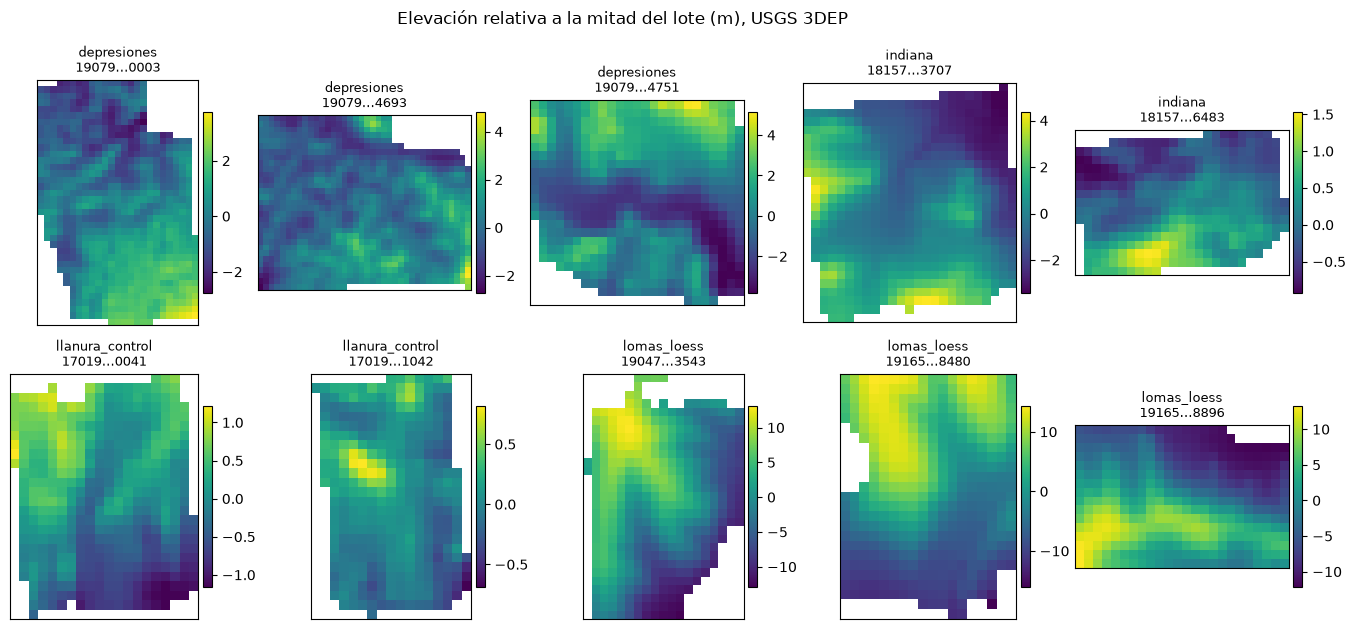

In [4]:
def grilla(d):
    # Fila y columna de cada píxel en la grilla de 30 m (fila 0 = norte)
    col = ((d["x_m"] - d["x_m"].min()) / 30).round().astype(int).to_numpy()
    fil = ((d["y_m"].max() - d["y_m"]) / 30).round().astype(int).to_numpy()
    return fil, col


def dibujar_lotes(tabla, columna, titulo, categorias=None, colores=None, cmap="viridis", subtitulos=None):
    # Un mapa chico por lote, ordenados por paisaje
    ids = list(lotes.sort_values(["paisaje", "id_lote"])["id_lote"])
    fig, ejes = plt.subplots(2, 5, figsize=(17, 7))
    for eje, id_lote in zip(ejes.flat, ids):
        d = tabla[tabla["id_lote"] == id_lote]
        fil, col = grilla(d)
        M = np.full((fil.max() + 1, col.max() + 1), np.nan)
        if categorias is None:
            M[fil, col] = d[columna].to_numpy(float)
            im = eje.imshow(M, cmap=cmap, interpolation="nearest")
            fig.colorbar(im, ax=eje, fraction=0.04, pad=0.02)
        else:
            M[fil, col] = d[columna].map({c: i for i, c in enumerate(categorias)}).to_numpy(float)
            eje.imshow(M, cmap=ListedColormap(colores), vmin=-0.5, vmax=len(categorias) - 0.5,
                       interpolation="nearest")
        paisaje = lotes.set_index("id_lote").loc[id_lote, "paisaje"]
        texto = f"{paisaje}\n{id_lote[:5]}…{id_lote[-4:]}"
        if subtitulos is not None:
            texto += "\n" + subtitulos.get(id_lote, "")
        eje.set_title(texto, fontsize=9)
        eje.set_xticks([]); eje.set_yticks([])
    if categorias is not None:
        fig.legend([Patch(color=c) for c in colores], categorias, loc="lower center", ncol=len(categorias))
    fig.suptitle(titulo)
    plt.show()


if HAY_DATOS:
    px = (pixeles[CLAVES + ["x_m", "y_m"]]
          .merge(terreno, on=CLAVES, validate="one_to_one")
          .merge(drenaje, on=CLAVES, how="left", validate="one_to_one"))
    px["elev_rel_m"] = px["elevacion_3dep_m"] - px.groupby("id_lote")["elevacion_3dep_m"].transform("median")
    display(lotes[["id_lote", "paisaje", "area_ha", "n_px_interior", "relieve_3dep_m"]]
            .sort_values(["paisaje", "id_lote"]).round(1))
    dibujar_lotes(px, "elev_rel_m", "Elevación relativa a la mitad del lote (m), USGS 3DEP", cmap="viridis")
else:
    print("Faltan los datos de lotes: queda en espera.")

## 3. Preparar las variables

Cuatro cosas:

1. **Suelo por píxel.** Un píxel puede caer en más de una unidad de suelo de SSURGO: promediamos ponderando por la fracción de cada una. Usamos el agua que el suelo puede guardar (`aws0_150_mm`) y el drenaje, pasado a un número de 0 (excesivamente drenado) a 6 (muy pobremente drenado).
2. **Años que sirven.** Un año entra si el lote tuvo maíz o soja, no estaba partido entre cultivos y al menos la mitad de los píxeles tienen una imagen despejada de julio–agosto. Antes de 2008 no sabemos qué cultivo había, así que esos años quedan afuera.
3. **Píxeles con otro cultivo.** Si un año el CDL dice que un píxel tenía otro cultivo que el lote (pasto en una vía de agua, soja en un lote de maíz), ese año el píxel no cuenta: su verdor no es el del cultivo del lote. En una prueba, un sector chico de un lote de Crawford (19047) tenía otro cultivo en el 69 % de sus píxel-años, y sin este paso salía como "loma seca". Con este paso, ese lote pasa a tener sectores débiles (paso 11): buena parte de lo que separaba sus sectores era ese otro cultivo. Guardamos la marca `otro_cultivo` para avisar en el sector (paso 13).
4. **Vigor relativo de cada año.** El NDVI cambia mucho de un año a otro (por el clima y por el cultivo), así que comparamos cada píxel **con el resto de su lote ese mismo año**:
   - `vigor_z` (**puntaje z**): cuántos desvíos está el píxel por encima (+) o por debajo (−) del promedio del lote. Es la escala que usa el modelo.
   - `vigor_rel_pct`: lo mismo en %, "este píxel tuvo 4 % más verdor que el promedio del lote". Es la que se muestra en la app.

   Las dos se calculan con un solo año a la vez, así que no mezclan información de un año con otro.

In [5]:
DRENAJE_ORDEN = {   # de más seco (0) a más húmedo (6)
    "Excessively drained": 0, "Somewhat excessively drained": 1, "Well drained": 2,
    "Moderately well drained": 3, "Somewhat poorly drained": 4, "Poorly drained": 5,
    "Very poorly drained": 6,
}
SUELO_NUMERICO = ["aws0_150_mm", "drenaje_ord"]


def promedio_ponderado(s, columna):
    # Promedio de una columna del suelo por píxel, ponderado por la fracción de cada unidad
    ok = s[columna].notna()
    t = s[ok].assign(_peso_x_valor=s.loc[ok, columna] * s.loc[ok, "frac_mukey"])
    g = t.groupby(CLAVES)
    return (g["_peso_x_valor"].sum() / g["frac_mukey"].sum()).rename(columna)


if HAY_DATOS:
    suelo_mk["drenaje_ord"] = suelo_mk["clase_drenaje"].map(DRENAJE_ORDEN)
    s = suelo_px.merge(suelo_mk, on="mukey")
    suelo = pd.concat([promedio_ponderado(s, c) for c in SUELO_NUMERICO], axis=1).reset_index()
    dominante = s.sort_values("frac_mukey").groupby(CLAVES).tail(1)[CLAVES + ["mukey", "clase_drenaje"]]
    px = (px.merge(suelo, on=CLAVES, how="left", validate="one_to_one")
            .merge(dominante, on=CLAVES, how="left", validate="one_to_one"))
    print("Píxeles:", len(px), "| sin dato de agua útil del suelo:", px["aws0_150_mm"].isna().sum())
else:
    print("Faltan los datos de lotes: queda en espera.")

Píxeles: 5334 | sin dato de agua útil del suelo: 0


Ahora los puntos 2, 3 y 4: qué años sirven en cada lote, qué píxel-años se sacan por tener otro cultivo y el vigor relativo de cada píxel en cada año. La tabla de abajo muestra cuántos años quedan por lote y qué % de los píxel-años tenía otro cultivo.

In [6]:
CULTIVOS_OK = ["maiz", "soja"]
MIN_FRAC_CON_DATO = 0.5   # al menos la mitad de los píxeles con imagen despejada en julio–agosto

if HAY_DATOS:
    veg = vegetacion.merge(pixeles[CLAVES], on=CLAVES, validate="many_to_one")   # solo píxeles interiores
    veg["ndvi"] = veg["ndvi_media_jul_ago"].where(veg["n_obs_jul_ago"] >= 1)
    veg = veg.merge(lotes_anio[["id_lote", "anio", "cultivo_principal", "lote_partido"]],
                    on=["id_lote", "anio"], how="left", validate="many_to_one")
    veg = veg.merge(cultivo_px.rename(columns={"cultivo": "cultivo_px"}),
                    on=CLAVES + ["anio"], how="left", validate="one_to_one")
    frac = veg.groupby(["id_lote", "anio"])["ndvi"].transform(lambda x: x.notna().mean())
    sirve = (veg["cultivo_principal"].isin(CULTIVOS_OK) & (veg["lote_partido"] == 0)
             & (frac >= MIN_FRAC_CON_DATO))
    veg = veg[sirve].copy()

    # Píxel-año con otro cultivo que el lote: no cuenta (si el CDL no tiene dato, se deja)
    veg["otro_cultivo"] = veg["cultivo_px"].notna() & (veg["cultivo_px"] != veg["cultivo_principal"])
    veg["ndvi"] = veg["ndvi"].mask(veg["otro_cultivo"])

    g = veg.groupby(["id_lote", "anio"])["ndvi"]
    veg["vigor_z"] = (veg["ndvi"] - g.transform("mean")) / g.transform("std")
    veg["vigor_rel_pct"] = 100 * (veg["ndvi"] / g.transform("mean") - 1)

    ANIOS = veg.groupby("id_lote")["anio"].apply(lambda a: sorted(a.unique())).to_dict()
    tabla = pd.DataFrame({
        "paisaje": lotes.set_index("id_lote")["paisaje"],
        "anios_que_sirven": pd.Series({k: len(v) for k, v in ANIOS.items()}),
        "desde": pd.Series({k: min(v) for k, v in ANIOS.items()}),
        "hasta": pd.Series({k: max(v) for k, v in ANIOS.items()}),
        "pct_px_anios_otro_cultivo": 100 * veg.groupby("id_lote")["otro_cultivo"].mean(),
    }).sort_values("paisaje").round(1)
    display(tabla)
else:
    print("Faltan los datos de lotes: queda en espera.")

,paisaje,anios_que_sirven,desde,hasta,pct_px_anios_otro_cultivo
19079_191825000600003,depresiones,11,2011,2025,0.0
19079_191825001174693,depresiones,13,2008,2025,0.4
19079_191825002094751,depresiones,14,2008,2025,0.5
18157_181825000203707,indiana,18,2008,2025,0.9
18157_181825001116483,indiana,18,2008,2025,1.2
17019_171825005060041,llanura_control,17,2008,2025,0.1
17019_171825005511042,llanura_control,14,2011,2025,0.5
19047_191825002083543,lomas_loess,16,2008,2025,2.6
19165_191825001638480,lomas_loess,12,2012,2025,1.0
19165_191825002368896,lomas_loess,14,2008,2025,0.2


**Años secos, normales y húmedos.** Para cada lote ordenamos sus años por el **déficit de agua de la temporada** (lluvia menos lo que pide la atmósfera, abril–septiembre, NASA POWER en el centro del lote): el tercio con más déficit es `seco`, el tercio con menos es `humedo` y el resto `normal`. La función recibe la lista de años a usar, así en la validación los cortes salen solo de los años de entrenamiento.

In [7]:
def clasificar_anios(id_lote, anios):
    c = clima[(clima["id_lote"] == id_lote) & clima["anio"].isin(anios)][["anio", "deficit_temporada_mm"]].copy()
    q1, q2 = c["deficit_temporada_mm"].quantile([1 / 3, 2 / 3])
    c["clase_anio"] = np.select([c["deficit_temporada_mm"] <= q1, c["deficit_temporada_mm"] >= q2],
                                ["seco", "humedo"], "normal")
    return c[["anio", "clase_anio"]]


if HAY_DATOS:
    ejemplo = lotes["id_lote"].iloc[0]
    print("Ejemplo,", ejemplo)
    display(clasificar_anios(ejemplo, ANIOS[ejemplo]).set_index("anio").T)
else:
    print("Faltan los datos de lotes: queda en espera.")

Ejemplo, 17019_171825005060041


anio,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2022,2023,2024,2025
clase_anio,humedo,humedo,normal,normal,seco,normal,humedo,humedo,humedo,seco,seco,humedo,normal,seco,seco,normal,seco


## 4. Split: dejar un año afuera

Acá no hay una respuesta correcta para copiar (no sabemos cuáles son los sectores "verdaderos"), así que la pregunta es otra: **si armo los sectores sin mirar un año, ¿explican cómo creció el cultivo ese año?** Si los sectores son reales, el bajo que se anega o la loma que se seca se tienen que repetir en años nuevos.

Cómo se hace, para cada lote:

1. Se saca un año (por ejemplo 2016).
2. Con los demás años se calculan las variables de vigor de cada píxel y se arman los sectores.
3. Se mide qué parte de las diferencias de vigor entre píxeles de 2016 explican esos sectores. Eso es el **R²**: 0 = nada, 1 = todo. Por ejemplo, 0,20 quiere decir que los sectores explican el 20 % de las diferencias de ese año; el resto cambia de un año a otro.
4. Se repite con cada año.

**El año 2025 queda guardado** para el examen final (paso 9): no entra en ninguna comparación hasta el final, igual que en el punto 2.

Las variables de vigor de cada píxel, calculadas solo con los años que se le pasan:

- `vigor_medio_z`: su vigor relativo promedio;
- `vigor_seco_z`: el promedio en los años secos;
- `vigor_humedo_z`: el promedio en los años húmedos.

Las dos últimas son las que distinguen una loma que se seca (le va mal en los años secos) de un bajo que se anega (le va mal en los húmedos).

In [8]:
ANIOS_TEST = [2025]


def armar_vigor(id_lote, anios):
    # Variables de vigor de cada píxel usando SOLO los años de la lista
    v = veg[(veg["id_lote"] == id_lote) & veg["anio"].isin(anios)]
    v = v.merge(clasificar_anios(id_lote, anios), on="anio", validate="many_to_one")
    f = v.groupby("px_id")["vigor_z"].mean().rename("vigor_medio_z").to_frame()
    for clase in ["seco", "humedo"]:
        f[f"vigor_{clase}_z"] = v[v["clase_anio"] == clase].groupby("px_id")["vigor_z"].mean()
    return f.reset_index()


def r2_sectores(y, sectores):
    # Qué parte de la variación de y (vigor de un año) explican los sectores
    ok = ~np.isnan(y)
    y, s = y[ok], sectores[ok]
    if len(np.unique(s)) < 2:
        return 0.0
    total = ((y - y.mean()) ** 2).sum()
    dentro = sum(((y[s == c] - y[s == c].mean()) ** 2).sum() for c in np.unique(s))
    return 1 - dentro / total


def diferencia_vigor(rel, sectores):
    # Diferencia de vigor (%) entre el mejor y el peor sector en un año
    medias = pd.Series(rel).groupby(sectores).mean()
    return medias.max() - medias.min()


if HAY_DATOS:
    ANIOS_DEV = {k: [a for a in v if a not in ANIOS_TEST] for k, v in ANIOS.items()}
    print("Años para comparar métodos por lote:", {k[-6:]: len(v) for k, v in ANIOS_DEV.items()})
else:
    print("Faltan los datos de lotes: queda en espera.")

Años para comparar métodos por lote: {'060041': 16, '511042': 13, '203707': 17, '116483': 17, '083543': 15, '600003': 10, '174693': 12, '094751': 13, '638480': 11, '368896': 13}


# Parte A · Elegir el método

## 5. Baseline: las reglas simples a superar

Un **baseline** es una regla tonta que el modelo tiene que superar. Si no le gana, no aporta nada. Usamos dos:

- **Regla de la elevación:** se parte el lote en tercios según la altura: el tercio más alto, el del medio y el más bajo. Es lo que haría alguien con un mapa topográfico.
- **Regla del vigor histórico:** se parte el lote en tercios según el vigor promedio de los otros años. Es lo que hace un agrónomo con un mapa de NDVI de varios años, sin ningún modelo.

In [9]:
def cortar_en_partes(x, k):
    # Parte una columna en k grupos del mismo tamaño (terciles si k = 3)
    cortes = np.nanquantile(x, np.linspace(0, 1, k + 1)[1:-1])
    return np.digitize(x, cortes)


def regla_elevacion(datos, k):
    return cortar_en_partes(datos["elev_rel_m"].to_numpy(), k)


def regla_vigor_historico(datos, k):
    return cortar_en_partes(datos["vigor_medio_z"].to_numpy(), k)


print("Reglas listas.")

Reglas listas.


## 6. Los métodos de agrupamiento

Los tres métodos **agrupan píxeles parecidos** sin que nadie les diga la respuesta (esto se llama aprendizaje **no supervisado**):

- **k-means:** pone k centros y asigna cada píxel al más cercano. Cada píxel va a un solo sector.
- **Fuzzy c-means (FCM):** igual que k-means, pero cada píxel tiene una **pertenencia** de 0 a 1 a cada sector ("este píxel es 70 % del bajo"). Así se ven las zonas de transición. `M_FCM` controla cuán difusos son los bordes: 2 es el valor habitual.
- **Mezcla gaussiana bayesiana (BGMM):** supone que los píxeles salen de varias "campanas" y apaga sola las que sobran, así que elige cuántos sectores hay. Como los píxeles vecinos se parecen mucho, se ajusta con 1 de cada 4 píxeles (una grilla de 2 × 2) y después se asignan todos; si no, parte el lote de más.

Probamos fuzzy c-means con tres juegos de variables, para ver qué aporta cada uno:

- `fcm_vigor`: solo el vigor de los otros años;
- `fcm_terreno_suelo`: solo terreno y suelo (no necesita imágenes);
- `fcm_todo`: las tres cosas juntas.

Antes de agrupar, cada variable se **estandariza** (se lleva a la misma escala), cada grupo de variables pesa lo mismo, se saca una de cada par muy parecido (correlación mayor a 0,9) y se resume con **PCA**, que junta columnas que dicen casi lo mismo.

Después de agrupar se aplica el **filtro de mayoría**: cada píxel toma el sector más común entre sus 8 vecinos. Así quedan sectores que una sembradora puede seguir, sin puntitos sueltos.

In [10]:
# Columnas que entran a los métodos, juntas acá
VAR_VIGOR = ["vigor_medio_z", "vigor_seco_z", "vigor_humedo_z"]
VAR_TERRENO = ["elev_rel_m", "twi_3dep", "pendiente_3dep_pct", "tpi_90m_3dep_m", "prof_depresion_3dep_m"]   # 3DEP
VAR_SUELO = ["aws0_150_mm", "drenaje_ord"]
M_FCM = 2.0
K_MAX_BGMM = 6
ALFA_BGMM = 0.01     # prior de Dirichlet: chico = apaga las campanas que sobran


def quitar_parecidas(datos, columnas, umbral=0.9):
    # Deja una de cada par de columnas con correlación > umbral (y saca las constantes)
    elegidas = []
    for c in columnas:
        if datos[c].std() > 1e-9 and all(abs(datos[c].corr(datos[e])) <= umbral for e in elegidas):
            elegidas.append(c)
    return elegidas


def preparar_matriz(datos, grupos):
    # Estandariza, da el mismo peso a cada grupo de variables y resume con PCA (90 % de la varianza)
    bloques = []
    for grupo in grupos:
        cols = quitar_parecidas(datos, grupo)
        if not cols:
            continue
        X = datos[cols].to_numpy(float)
        X = np.where(np.isnan(X), np.nanmedian(X, axis=0), X)   # píxel sin dato: la mediana del lote
        X = (X - X.mean(0)) / X.std(0)
        bloques.append(X / np.sqrt(len(cols)))
    return PCA(n_components=0.9, svd_solver="full").fit_transform(np.hstack(bloques))


def fuzzy_cmeans(X, k, m=M_FCM, n_init=3, max_iter=300, tol=1e-6, semilla=SEMILLA):
    # Devuelve los centros y la pertenencia de cada píxel a cada sector (filas que suman 1)
    rng = np.random.default_rng(semilla)
    mejor = None
    for _ in range(n_init):
        U = rng.dirichlet(np.ones(k), size=len(X))
        for _ in range(max_iter):
            Um = U ** m
            C = (Um.T @ X) / Um.sum(0)[:, None]
            dist = np.linalg.norm(X[:, None, :] - C[None], axis=2) + 1e-12
            inv = dist ** (-2 / (m - 1))
            U_nueva = inv / inv.sum(1, keepdims=True)
            listo = np.abs(U_nueva - U).max() < tol
            U = U_nueva
            if listo:
                break
        costo = ((U ** m) * dist ** 2).sum()
        if mejor is None or costo < mejor[0]:
            mejor = (costo, C, U)
    return mejor[1], mejor[2]


def bgmm_con_raleo(X, fil, col):
    # Ajusta con 1 de cada 4 píxeles y asigna todos, solo a las campanas que quedaron prendidas
    muestra = (fil % 2 == 1) & (col % 2 == 1)
    g = BayesianGaussianMixture(n_components=K_MAX_BGMM, weight_concentration_prior=ALFA_BGMM,
                                covariance_type="full", max_iter=500, n_init=3,
                                random_state=SEMILLA).fit(X[muestra])
    P = g.predict_proba(X)
    P[:, g.weights_ < 0.02] = 0
    return P.argmax(1)


def filtro_mayoria(sectores, fil, col):
    # Cada píxel toma el sector más común entre él y sus 8 vecinos (si empata, se queda con el suyo)
    G = -np.ones((fil.max() + 3, col.max() + 3), int)
    G[fil + 1, col + 1] = sectores
    clases = np.unique(sectores)
    cuentas = np.zeros((len(clases), len(sectores)))
    for i, c in enumerate(clases):
        M = (G == c).astype(int)
        vecinos = sum(np.roll(np.roll(M, a, 0), b, 1) for a in (-1, 0, 1) for b in (-1, 0, 1))
        cuentas[i] = vecinos[fil + 1, col + 1]
    propio = cuentas[np.searchsorted(clases, sectores), np.arange(len(sectores))]
    return np.where(cuentas.max(0) > propio, clases[cuentas.argmax(0)], sectores)


METODOS = {
    "regla_elevacion":       regla_elevacion,
    "regla_vigor_historico": regla_vigor_historico,
    "kmeans_vigor":      lambda d, k: KMeans(k, n_init=10, random_state=SEMILLA).fit_predict(preparar_matriz(d, [VAR_VIGOR])),
    "fcm_vigor":         lambda d, k: fuzzy_cmeans(preparar_matriz(d, [VAR_VIGOR]), k)[1].argmax(1),
    "fcm_terreno_suelo": lambda d, k: fuzzy_cmeans(preparar_matriz(d, [VAR_TERRENO, VAR_SUELO]), k)[1].argmax(1),
    "fcm_todo":          lambda d, k: fuzzy_cmeans(preparar_matriz(d, [VAR_TERRENO, VAR_SUELO, VAR_VIGOR]), k)[1].argmax(1),
    "bgmm_vigor":        lambda d, k: bgmm_con_raleo(preparar_matriz(d, [VAR_VIGOR]), d["fila"].to_numpy(), d["columna"].to_numpy()),
}
print("Métodos:", list(METODOS))

Métodos: ['regla_elevacion', 'regla_vigor_historico', 'kmeans_vigor', 'fcm_vigor', 'fcm_terreno_suelo', 'fcm_todo', 'bgmm_vigor']


## 7. Comparar los métodos dejando un año afuera

Para cada lote, cada año de comparación y cada método, armamos los sectores sin ese año y medimos el R² en ese año. Probamos 2, 3 y 4 sectores (la app muestra de 2 a 4). La BGMM elige sola cuántos.

**Ojo:** más sectores siempre explican un poco más, así que la comparación justa es con la misma cantidad de sectores. La tabla principal usa 3.

Tarda unos minutos.

In [11]:
KS = [2, 3, 4]


def datos_lote(id_lote):
    d = px[px["id_lote"] == id_lote].sort_values("px_id").reset_index(drop=True)
    d["fila"], d["columna"] = grilla(d)
    return d


def validar_lote(id_lote, anios):
    d = datos_lote(id_lote)
    fil, col = d["fila"].to_numpy(), d["columna"].to_numpy()
    vl = veg[veg["id_lote"] == id_lote]
    y_anio = vl.pivot(index="px_id", columns="anio", values="vigor_z").reindex(d["px_id"])
    rel_anio = vl.pivot(index="px_id", columns="anio", values="vigor_rel_pct").reindex(d["px_id"])
    filas = []
    for anio in anios:
        otros = [a for a in anios if a != anio]
        datos = d.merge(armar_vigor(id_lote, otros), on="px_id", how="left", validate="one_to_one")
        y, rel = y_anio[anio].to_numpy(), rel_anio[anio].to_numpy()
        for metodo, funcion in METODOS.items():
            for k in ([None] if metodo == "bgmm_vigor" else KS):
                sectores = filtro_mayoria(np.asarray(funcion(datos, k)), fil, col)
                filas.append({"id_lote": id_lote, "anio_afuera": anio, "metodo": metodo,
                              "k_pedido": k, "k": len(np.unique(sectores)),
                              "r2": r2_sectores(y, sectores), "dif_vigor_pct": diferencia_vigor(rel, sectores)})
    return filas


if HAY_DATOS:
    filas = []
    for id_lote in lotes["id_lote"]:
        filas += validar_lote(id_lote, ANIOS_DEV[id_lote])
        print("listo", id_lote)
    resultados = pd.DataFrame(filas).merge(lotes[["id_lote", "paisaje"]], on="id_lote")
else:
    print("Faltan los datos de lotes: queda en espera.")

listo 17019_171825005060041


listo 17019_171825005511042


listo 18157_181825000203707


listo 18157_181825001116483


listo 19047_191825002083543


listo 19079_191825000600003


listo 19079_191825001174693


listo 19079_191825002094751


listo 19165_191825001638480


listo 19165_191825002368896


**R² mediano con 3 sectores, por paisaje.** Cada número es la mediana de todos los años dejados afuera. Más alto es mejor. La BGMM va con la cantidad de sectores que eligió ella (columna `k` de la segunda tabla).

In [12]:
if HAY_DATOS:
    r3 = resultados[(resultados["k_pedido"] == 3) | (resultados["metodo"] == "bgmm_vigor")]
    orden = ["regla_elevacion", "regla_vigor_historico", "fcm_terreno_suelo", "fcm_todo",
             "kmeans_vigor", "bgmm_vigor", "fcm_vigor"]
    tabla = r3.groupby(["paisaje", "metodo"])["r2"].median().unstack()[orden]
    tabla.loc["TOTAL"] = r3.groupby("metodo")["r2"].median()[orden]
    display(tabla.round(3))

    por_lote = r3.groupby(["id_lote", "metodo"])["r2"].median().unstack()
    resumen = pd.DataFrame({
        "r2_mediano": r3.groupby("metodo")["r2"].median(),
        "k": r3.groupby("metodo")["k"].mean(),
        "lotes_donde_gana_a_regla_vigor": (por_lote.gt(por_lote["regla_vigor_historico"], axis=0)).sum(),
    }).loc[orden]
    display(resumen.round(2))
else:
    print("Faltan los datos de lotes: queda en espera.")

metodo,regla_elevacion,regla_vigor_historico,fcm_terreno_suelo,fcm_todo,kmeans_vigor,bgmm_vigor,fcm_vigor
paisaje,,,,,,,
depresiones,0.068,0.131,0.052,0.107,0.168,0.202,0.188
indiana,0.106,0.151,0.107,0.140,0.183,0.152,0.180
llanura_control,0.054,0.063,0.077,0.073,0.065,0.031,0.069
lomas_loess,0.134,0.145,0.093,0.126,0.210,0.143,0.183
TOTAL,0.098,0.131,0.085,0.117,0.142,0.107,0.145


,r2_mediano,k,lotes_donde_gana_a_regla_vigor
metodo,,,
regla_elevacion,0.10,3.00,2
regla_vigor_historico,0.13,3.00,0
fcm_terreno_suelo,0.09,3.00,2
fcm_todo,0.12,3.00,5
kmeans_vigor,0.14,2.92,6
bgmm_vigor,0.11,2.71,4
fcm_vigor,0.15,3.00,7


**¿Cuántos sectores?** El mismo R² para 2, 3 y 4 sectores, con el método ganador y con la regla del vigor histórico:

In [13]:
if HAY_DATOS:
    por_k = (resultados[resultados["metodo"].isin(["fcm_vigor", "regla_vigor_historico"])]
             .groupby(["metodo", "k_pedido"])["r2"].median().unstack())
    display(por_k.round(3))
else:
    print("Faltan los datos de lotes: queda en espera.")

k_pedido,2.0,3.0,4.0
metodo,,,
fcm_vigor,0.092,0.145,0.184
regla_vigor_historico,0.082,0.131,0.135


**Qué muestran estas tablas** (corrida con la entrega v1.3, 14/11/2026):

- **El vigor de los otros años es lo que mejor arma los sectores.** `fcm_vigor` tiene el R² más alto (0,145) y le gana a la regla del vigor histórico (0,131) en 7 de los 10 lotes. La ventaja es chica.
- **Sacar los píxel-años con otro cultivo (paso 3) bajó el R²**, de 0,16 a 0,145. Parte de lo que "explicaban" los sectores era una franja con otro cultivo que se repetía año tras año, sobre todo en el lote de Crawford (19047). El número nuevo es el honesto.
- **Con el terreno de 3DEP, la elevación explica más que con NASADEM** (la regla de la elevación pasa de 0,04 a 0,10; `fcm_terreno_suelo`, de 0,05 a 0,085), pero sigue abajo del vigor, y **sumada al vigor lo empeora** (`fcm_todo`, 0,12). SSURGO tiene pocas unidades por lote y el terreno no sigue el patrón fino del vigor. Terreno y suelo los usamos para **nombrar y explicar** los sectores (Parte B), no para armarlos.
- **k-means da casi lo mismo que fuzzy c-means** (0,14, gana en 6 lotes). Nos quedamos con fuzzy c-means porque además da la pertenencia, que marca las zonas de transición. La BGMM queda atrás (0,11).
- **3 sectores:** de 2 a 3 el R² sube 0,05 y de 3 a 4, 0,04. Con 4 explica algo más, pero los sectores salen más chicos y la ficha es más difícil de leer. Seguimos con 3; queda anotado para revisar.
- **Aun el mejor método explica una parte chica** (alrededor del 15 %) de las diferencias de un año nuevo. El resto cambia de un año a otro: clima, manejo, plagas y ruido de la imagen. Por eso la app muestra rangos por tipo de año, no un número fijo.
- **Los lotes planos de control casi no tienen sectores** (R² de 0,07): es lo esperable, y le da sentido al resto.

Si cambian los datos, revisá que estas conclusiones sigan valiendo antes de tocar las dos constantes de abajo.

In [14]:
METODO_ELEGIDO = "fcm_vigor"
K_SECTORES = 3
print("Método:", METODO_ELEGIDO, "| sectores por lote:", K_SECTORES)

Método: fcm_vigor | sectores por lote: 3


## 8. ¿Y el chequeo previo con KDE?

La idea original era, antes de agrupar, mirar si los píxeles forman "montañas" separadas (picos de densidad, con KDE y mean shift) y, si hay un solo pico, decir "lote parejo".

Lo probamos con las dos primeras componentes del vigor. El ancho de banda `h` sale de la regla de Scott, contando 1 píxel independiente de cada 10, porque los vecinos se parecen. Contamos los picos que juntan al menos el 3 % de los píxeles.

In [15]:
def mean_shift(X, h, iters=200, tol=1e-5):
    # Cada punto sube por la "montaña" de densidad hasta su pico; los que llegan al mismo pico, mismo grupo
    Y = X.copy()
    for _ in range(iters):
        d2 = ((Y[:, None, :] - X[None]) ** 2).sum(2)
        W = np.exp(-d2 / (2 * h * h))
        Y_nueva = (W @ X) / W.sum(1, keepdims=True)
        listo = np.abs(Y_nueva - Y).max() < tol
        Y = Y_nueva
        if listo:
            break
    picos, grupo = [], np.empty(len(X), int)
    for i, y in enumerate(Y):
        for j, p in enumerate(picos):
            if np.linalg.norm(y - p) < h / 2:
                grupo[i] = j
                break
        else:
            picos.append(y)
            grupo[i] = len(picos) - 1
    return grupo


def contar_picos(X, min_pct=3.0):
    # Regla de Scott con n efectivo = N / 10; picos con al menos min_pct % de los píxeles
    W = X / X.std(0)
    h = (len(W) / 10) ** (-1 / (W.shape[1] + 4))
    pct = 100 * np.bincount(mean_shift(W, h)) / len(W)
    return int((pct >= min_pct).sum()), pct.max()


if HAY_DATOS:
    filas = []
    for id_lote in lotes["id_lote"]:
        datos = datos_lote(id_lote).merge(armar_vigor(id_lote, ANIOS_DEV[id_lote]), on="px_id", how="left")
        X = preparar_matriz(datos, [VAR_VIGOR])[:, :2]   # las dos primeras componentes
        n, mayor = contar_picos(X)
        filas.append({"id_lote": id_lote, "paisaje": lotes.set_index("id_lote").loc[id_lote, "paisaje"],
                      "picos": n, "pct_en_el_pico_mayor": round(mayor, 1)})
    picos_kde = pd.DataFrame(filas).sort_values("paisaje")
    display(picos_kde)
else:
    print("Faltan los datos de lotes: queda en espera.")

,id_lote,paisaje,picos,pct_en_el_pico_mayor
5,19079_191825000600003,depresiones,1,98.6
6,19079_191825001174693,depresiones,1,98.5
7,19079_191825002094751,depresiones,1,97.8
2,18157_181825000203707,indiana,1,99.5
3,18157_181825001116483,indiana,1,99.2
0,17019_171825005060041,llanura_control,1,99.3
1,17019_171825005511042,llanura_control,1,99.7
4,19047_191825002083543,lomas_loess,1,98.6
8,19165_191825001638480,lomas_loess,1,99.2
9,19165_191825002368896,lomas_loess,1,100.0


**Resultado:** en los 10 lotes sale **un solo pico** (con el 96–100 % de los píxeles), aun en las lomas de loess con 30 m de desnivel y en los lotes donde los sectores sí se repiten año tras año. En un lote real el vigor cambia de a poco a lo largo de la loma, sin "montañas" separadas, así que contar picos no dice si vale la pena dividir el lote.

Por eso **no usamos el KDE como filtro**. La decisión de "lote parejo" sale de la validación (paso 11): si los sectores no se repiten en años nuevos, o si la diferencia de vigor entre ellos es muy chica, el lote es parejo.

## 9. Examen final (2025)

Por eso la celda está apagada: cambiá `MIRAR_TEST` a `True` **solo cuando ya no vayas a cambiar nada del método**. Arma los sectores con todos los años hasta 2024 y mide el R² en 2025, contra las dos reglas. Si después de verlo se ajusta algo, el examen deja de ser honesto.

Ojo: el CDL de 2025 viene de 10 m, y en la exploración inicial (antes de armar esta notebook) se miraron todos los años, 2025 incluido. Este examen no es del todo ciego: tomalo como un control, no como una prueba perfecta.

In [16]:
MIRAR_TEST = False   # pasalo a True una sola vez, al final

if HAY_DATOS and MIRAR_TEST:
    filas = []
    for id_lote in lotes["id_lote"]:
        if 2025 not in ANIOS[id_lote]:
            continue
        d = datos_lote(id_lote)
        datos = d.merge(armar_vigor(id_lote, ANIOS_DEV[id_lote]), on="px_id", how="left")
        y = veg[(veg["id_lote"] == id_lote) & (veg["anio"] == 2025)].set_index("px_id")["vigor_z"].reindex(d["px_id"]).to_numpy()
        for metodo in ["regla_elevacion", "regla_vigor_historico", METODO_ELEGIDO]:
            s = filtro_mayoria(np.asarray(METODOS[metodo](datos, K_SECTORES)), d["fila"].to_numpy(), d["columna"].to_numpy())
            filas.append({"paisaje": lotes.set_index("id_lote").loc[id_lote, "paisaje"], "metodo": metodo, "r2": r2_sectores(y, s)})
    test = pd.DataFrame(filas)
    tabla = test.groupby(["paisaje", "metodo"])["r2"].median().unstack()
    tabla.loc["TOTAL"] = test.groupby("metodo")["r2"].median()
    display(tabla.round(3))
elif HAY_DATOS:
    print("Test 2025 sin mirar todavía (MIRAR_TEST = False).")
else:
    print("Faltan los datos de lotes: queda en espera.")

Test 2025 sin mirar todavía (MIRAR_TEST = False).


# Parte B · Sectores para la app

## 10. Armar los sectores con todos los años

Ya elegido el método, armamos los sectores de cada lote con **todos** sus años (2025 incluido): fuzzy c-means sobre el vigor, 3 sectores y filtro de mayoría. De cada píxel guardamos su sector y su **pertenencia** a ese sector (de 0 a 1: cerca de 1 es el centro del sector; más bajo, una zona de transición).

In [17]:
if HAY_DATOS:
    partes = []
    for id_lote in lotes["id_lote"]:
        d = datos_lote(id_lote)
        datos = d.merge(armar_vigor(id_lote, ANIOS[id_lote]), on="px_id", how="left", validate="one_to_one")
        _, U = fuzzy_cmeans(preparar_matriz(datos, [VAR_VIGOR]), K_SECTORES)
        sector = filtro_mayoria(U.argmax(1), d["fila"].to_numpy(), d["columna"].to_numpy())
        datos["sector"] = sector
        datos["pertenencia"] = U[np.arange(len(U)), sector]
        partes.append(datos)
    sectores_px = pd.concat(partes, ignore_index=True)
    print("Píxeles con sector:", len(sectores_px))
    print("Pertenencia mediana:", round(sectores_px["pertenencia"].median(), 2),
          "| píxeles en transición (pertenencia < 0,6):",
          f'{100 * (sectores_px["pertenencia"] < 0.6).mean():.0f} %')
else:
    print("Faltan los datos de lotes: queda en espera.")

Píxeles con sector: 5334
Pertenencia mediana: 0.81 | píxeles en transición (pertenencia < 0,6): 27 %


## 11. ¿Hay sectores o el lote es parejo?

Usamos lo que midió la validación del paso 7 con el método elegido, con dos preguntas:

- **¿los sectores se repiten en años nuevos?** El R² mediano de los años dejados afuera;
- **¿la diferencia importa?** Cuánto vigor (%) hay entre el mejor y el peor sector, en la mediana de los años dejados afuera.

Con eso, tres estados:

- `con_sectores`: R² de al menos `UMBRAL_R2` **y** diferencia de al menos `UMBRAL_DIF_VIGOR_PCT` %.
- `sectores_debiles`: no llega a eso, pero pasa los umbrales más bajos (`UMBRAL_R2_DEBIL` y `UMBRAL_DIF_DEBIL_PCT`). Los sectores se guardan, todos con confianza `baja`.
- `lote_parejo`: el resto. La app no pinta sectores.

¿Por qué un estado del medio? Los umbrales son **supuestos** elegidos mirando estos 10 lotes, y moviéndolos dentro de valores razonables (R² de 0,05 a 0,15; diferencia de 1,5 a 3 %) la cantidad de lotes con sectores va de 4 a 7. Un sí o no tajante haría depender el mapa de un corte que no conocemos bien. Con más lotes hay que revisarlos.

`sectores_debiles` todavía no está en el contrato del front (`INFO.md`), donde `estado_sectores` es un campo firme: sumarlo hay que acordarlo con el equipo del front.

In [18]:
UMBRAL_R2 = 0.10
UMBRAL_DIF_VIGOR_PCT = 2.0
UMBRAL_R2_DEBIL = 0.05
UMBRAL_DIF_DEBIL_PCT = 1.5

if HAY_DATOS:
    elegido = resultados[(resultados["metodo"] == METODO_ELEGIDO) & (resultados["k_pedido"] == K_SECTORES)]
    estado = elegido.groupby("id_lote").agg(r2_validacion=("r2", "median"),
                                            dif_vigor_validacion_pct=("dif_vigor_pct", "median"),
                                            anios_validacion=("anio_afuera", "size"))
    r2, dif = estado["r2_validacion"], estado["dif_vigor_validacion_pct"]
    estado["estado_sectores"] = np.select(
        [(r2 >= UMBRAL_R2) & (dif >= UMBRAL_DIF_VIGOR_PCT),
         (r2 >= UMBRAL_R2_DEBIL) & (dif >= UMBRAL_DIF_DEBIL_PCT)],
        ["con_sectores", "sectores_debiles"], "lote_parejo")
    estado = estado.join(lotes.set_index("id_lote")[["paisaje", "relieve_3dep_m"]])
    display(estado.sort_values("paisaje").round(3))
else:
    print("Faltan los datos de lotes: queda en espera.")

,r2_validacion,dif_vigor_validacion_pct,anios_validacion,estado_sectores,paisaje,relieve_3dep_m
id_lote,,,,,,
19079_191825000600003,0.093,1.073,10,lote_parejo,depresiones,7.35
19079_191825001174693,0.183,5.587,12,con_sectores,depresiones,7.71
19079_191825002094751,0.284,9.543,13,con_sectores,depresiones,9.13
18157_181825000203707,0.228,4.675,17,con_sectores,indiana,8.28
18157_181825001116483,0.097,2.119,17,sectores_debiles,indiana,2.47
17019_171825005060041,0.069,1.157,16,lote_parejo,llanura_control,2.68
17019_171825005511042,0.069,0.980,13,lote_parejo,llanura_control,1.60
19047_191825002083543,0.089,3.477,15,sectores_debiles,lomas_loess,26.12
19165_191825001638480,0.124,3.530,11,con_sectores,lomas_loess,31.18


## 12. Cómo le va a cada sector según el año

Para cada sector y cada año: cuánto más (+) o menos (−) vigor tuvo que el promedio del lote, en %. Eso es `vigor_rel_pct`, lo que muestra la ficha del sector en la app.

Después lo resumimos por tipo de año (seco, normal, húmedo) con la **mediana** y el rango de **p10 a p90**: en 1 de cada 10 años le fue peor que el p10, y en 1 de cada 10, mejor que el p90.

`n_obs_jul_ago` es la cantidad mediana de imágenes despejadas de julio–agosto de ese año. Con pocas (1 o 2), el punto de ese año es menos confiable.

Los píxel-años con otro cultivo (paso 3) no entran: el vigor del sector es el del cultivo del lote.

In [19]:
if HAY_DATOS:
    v = veg.merge(sectores_px[["id_lote", "px_id", "sector"]], on=["id_lote", "px_id"])
    lote_media = v.groupby(["id_lote", "anio"])["ndvi"].mean().rename("ndvi_lote")
    serie = (v.groupby(["fips", "id_lote", "sector", "anio"])
              .agg(ndvi_sector=("ndvi", "mean"), n_px_con_dato=("ndvi", "count"),
                   n_obs_jul_ago=("n_obs_jul_ago", "median"), cultivo=("cultivo_principal", "first"))
              .reset_index().join(lote_media, on=["id_lote", "anio"]))
    serie["vigor_rel_pct"] = 100 * (serie["ndvi_sector"] / serie["ndvi_lote"] - 1)
    clases = pd.concat([clasificar_anios(i, ANIOS[i]).assign(id_lote=i) for i in ANIOS])
    serie = serie.merge(clases, on=["id_lote", "anio"])

    def p10(x): return np.percentile(x, 10)
    def p90(x): return np.percentile(x, 90)

    por_clase = (serie.groupby(["id_lote", "sector", "clase_anio"])["vigor_rel_pct"]
                 .agg(mediana="median", p10=p10, p90=p90, n_anios="size").reset_index())
    print("Filas de la serie (sector × año):", len(serie))
else:
    print("Faltan los datos de lotes: queda en espera.")

Filas de la serie (sector × año): 441


**¿Se cumple lo que dice la ficha en un año nuevo?** La ficha del sector dice cosas como "en los años secos queda abajo del promedio del lote". Para saber si eso se sostiene, lo medimos **fuera de muestra**, igual que en el paso 7. Para cada año:

1. armamos los sectores sin ese año;
2. buscamos el sector armado sin ese año que más se superpone con cada sector final;
3. con los otros años del mismo tipo (seco, normal o húmedo) vemos de qué lado del promedio quedó ese sector;
4. miramos si en el año que dejamos afuera quedó del mismo lado.

La **consistencia** (`pct_anios_consistente`) es el % de años en que acertó. Se mide dentro de cada tipo de año porque un bajo húmedo puede estar arriba del promedio en los años secos y abajo en los húmedos, y eso es justo lo que lo define.

Si la midiéramos con los mismos años que armaron los sectores, saldría más alta de lo que es. En una prueba con la entrega v1.2, en dos lotes daba 83–86 % así y 64 % fuera de muestra.

In [20]:
def consistencia_fuera_de_muestra(id_lote):
    # Una fila por sector final y año: ¿quedó del lado esperado, armando los sectores sin ese año?
    d = datos_lote(id_lote)
    fil, col = d["fila"].to_numpy(), d["columna"].to_numpy()
    final = sectores_px[sectores_px["id_lote"] == id_lote].set_index("px_id")["sector"].reindex(d["px_id"]).to_numpy()
    rel = veg[veg["id_lote"] == id_lote].pivot(index="px_id", columns="anio", values="vigor_rel_pct").reindex(d["px_id"])
    anios = ANIOS[id_lote]
    clase = clasificar_anios(id_lote, anios).set_index("anio")["clase_anio"]
    filas = []
    for anio in anios:
        otros = [a for a in anios if a != anio]
        mismos = [a for a in otros if clase[a] == clase[anio]]
        if not mismos:
            continue
        datos = d.merge(armar_vigor(id_lote, otros), on="px_id", how="left", validate="one_to_one")
        _, U = fuzzy_cmeans(preparar_matriz(datos, [VAR_VIGOR]), K_SECTORES)
        sin_anio = filtro_mayoria(U.argmax(1), fil, col)
        for s in np.unique(final):
            par = sin_anio == pd.Series(sin_anio[final == s]).mode().iloc[0]
            esperado = np.sign(np.median([np.nanmean(rel[a].to_numpy()[par]) for a in mismos]))
            real = np.sign(np.nanmean(rel[anio].to_numpy()[par]))
            if not (np.isnan(esperado) or np.isnan(real)):
                filas.append({"id_lote": id_lote, "sector": s, "anio": anio, "acierto": esperado == real})
    return filas


if HAY_DATOS:
    filas = []
    for id_lote in lotes["id_lote"]:
        filas += consistencia_fuera_de_muestra(id_lote)
    aciertos = pd.DataFrame(filas)
    consistencia = (100 * aciertos.groupby(["id_lote", "sector"])["acierto"].mean()).rename("pct_anios_consistente")
    print("Consistencia mediana fuera de muestra:", round(consistencia.median()), "%")
else:
    print("Faltan los datos de lotes: queda en espera.")

Consistencia mediana fuera de muestra: 83 %


## 13. Ponerle nombre a cada sector y medir la confianza

Esto es una **regla**, no sale del modelo (la app lo marca como "Agronomic rule"). Primero se ordenan los 3 sectores por vigor: `vigor_alto`, `zona_media` y `vigor_bajo`. Después, si el terreno y el comportamiento lo justifican, se cambia el nombre:

- **`loma_seca`:** está al menos `UMBRAL_ELEV_M` más alto que la mitad del lote, **y** en los años secos le va peor que al promedio del lote **y** peor que en sus años húmedos (al menos `UMBRAL_SENAL_Z` de diferencia). Si hay más de uno, el más alto.
- **`bajo_humedo`:** lo mismo al revés: al menos `UMBRAL_ELEV_M` más bajo, y en los años húmedos le va peor que al promedio del lote y peor que en sus años secos. Si hay más de uno, el más bajo.

Así, un sector alto al que le va bien todos los años no se llama "loma seca": el nombre tiene que coincidir con lo que pasa en el lote.

`vigor_alto` y `vigor_bajo` son nombres nuevos: hay que sumarlos al contrato del front (`INFO.md`) y a `textos.json`.

**Confianza** del sector, con la consistencia fuera de muestra del paso 12:

- `alta`: acertó en al menos el 80 % de los años, y el lote tiene R² de al menos 0,20;
- `media`: al menos el 65 % de los años;
- `baja`: el resto. También es `baja`, sin importar lo demás, si el lote tiene `sectores_debiles` o si en más de `UMBRAL_OTRO_CULTIVO_PCT` % de los píxel-años del sector había otro cultivo (puede ser una vía de agua, un borde o un pedazo de otro lote).

Dos rasgos más, que no entran en el nombre pero sirven para explicarlo:

- `pct_drenaje_canos`: % del sector con drenaje con caños enterrados, según el mapa AgTile-US. Es un mapa modelado a partir de suelo, pendiente y uso agrícola, no un registro de cada lote: sirve como indicio.
- `pct_otro_cultivo`: % de los píxel-años del sector con otro cultivo que el lote.

Los umbrales son supuestos y están todos juntos acá abajo.

In [21]:
UMBRAL_ELEV_M = 0.5            # metros por encima o por debajo de la mitad del lote
UMBRAL_SENAL_Z = 0.25          # diferencia de vigor (puntaje z) entre años secos y húmedos
CONSISTENCIA_ALTA, CONSISTENCIA_MEDIA = 80, 65
R2_PARA_ALTA = 0.20
UMBRAL_OTRO_CULTIVO_PCT = 25   # más que esto: confianza baja


def nombrar_sectores(t):
    # t: una fila por sector de un lote, con elev_rel_m y las variables de vigor
    t = t.sort_values("vigor_medio_z", ascending=False).copy()
    t["tipo"] = ["vigor_alto"] + ["zona_media"] * (len(t) - 2) + ["vigor_bajo"]
    sufre_seca = (t["vigor_seco_z"] - t["vigor_humedo_z"]) <= -UMBRAL_SENAL_Z
    sufre_humedo = (t["vigor_humedo_z"] - t["vigor_seco_z"]) <= -UMBRAL_SENAL_Z
    loma = t[(t["elev_rel_m"] >= UMBRAL_ELEV_M) & sufre_seca & (t["vigor_seco_z"] < 0)]
    if len(loma):
        t.loc[loma["elev_rel_m"].idxmax(), "tipo"] = "loma_seca"
    bajo = t[(t["elev_rel_m"] <= -UMBRAL_ELEV_M) & sufre_humedo & (t["vigor_humedo_z"] < 0)
             & (t["tipo"] != "loma_seca")]
    if len(bajo):
        t.loc[bajo["elev_rel_m"].idxmin(), "tipo"] = "bajo_humedo"
    t["sector_id"] = range(1, len(t) + 1)   # 1 = el de más vigor
    return t


def clase_mas_comun(x):
    x = x.dropna()
    return x.mode().iloc[0] if len(x) else np.nan


if HAY_DATOS:
    rasgos = (sectores_px.groupby(["fips", "id_lote", "sector"])
              .agg(n_px=("px_id", "size"), pertenencia_media=("pertenencia", "mean"),
                   elev_rel_m=("elev_rel_m", "mean"), pendiente_3dep_pct=("pendiente_3dep_pct", "mean"),
                   twi_3dep=("twi_3dep", "mean"), aws0_150_mm=("aws0_150_mm", "mean"),
                   clase_drenaje=("clase_drenaje", clase_mas_comun),
                   pct_drenaje_canos=("drenado_canos", lambda x: 100 * x.mean()),
                   vigor_medio_z=("vigor_medio_z", "mean"), vigor_seco_z=("vigor_seco_z", "mean"),
                   vigor_humedo_z=("vigor_humedo_z", "mean"))
              .reset_index())
    otro = (veg.merge(sectores_px[["id_lote", "px_id", "sector"]], on=["id_lote", "px_id"], validate="many_to_one")
            .groupby(["id_lote", "sector"])["otro_cultivo"].mean().mul(100).rename("pct_otro_cultivo"))
    rasgos = rasgos.join(otro, on=["id_lote", "sector"])
    rasgos["pct_lote"] = 100 * rasgos["n_px"] / rasgos.groupby("id_lote")["n_px"].transform("sum")
    rasgos["area_ha"] = rasgos["n_px"] * 0.09
    rasgos = pd.concat([nombrar_sectores(t) for _, t in rasgos.groupby("id_lote")], ignore_index=True)
    rasgos = rasgos.join(consistencia, on=["id_lote", "sector"]).join(estado, on="id_lote")
    rasgos["confianza"] = np.select(
        [(rasgos["estado_sectores"] == "sectores_debiles") | (rasgos["pct_otro_cultivo"] > UMBRAL_OTRO_CULTIVO_PCT),
         (rasgos["pct_anios_consistente"] >= CONSISTENCIA_ALTA) & (rasgos["r2_validacion"] >= R2_PARA_ALTA),
         rasgos["pct_anios_consistente"] >= CONSISTENCIA_MEDIA], ["baja", "alta", "media"], "baja")
    ver = ["paisaje", "id_lote", "estado_sectores", "sector_id", "tipo", "pct_lote", "elev_rel_m",
           "twi_3dep", "aws0_150_mm", "clase_drenaje", "pct_drenaje_canos", "pct_otro_cultivo",
           "vigor_seco_z", "vigor_humedo_z", "pct_anios_consistente", "confianza"]
    display(rasgos[ver].sort_values(["paisaje", "id_lote", "sector_id"]).round(2))
else:
    print("Faltan los datos de lotes: queda en espera.")

,paisaje,id_lote,estado_sectores,sector_id,tipo,pct_lote,elev_rel_m,twi_3dep,aws0_150_mm,clase_drenaje,pct_drenaje_canos,pct_otro_cultivo,vigor_seco_z,vigor_humedo_z,pct_anios_consistente,confianza
15,depresiones,19079_191825000600003,lote_parejo,1,bajo_humedo,30.31,-0.52,7.92,229.26,Poorly drained,63.49,0.00,0.68,-0.24,63.64,baja
16,depresiones,19079_191825000600003,lote_parejo,2,zona_media,50.94,0.36,8.06,225.91,Poorly drained,80.49,0.00,-0.28,0.40,63.64,baja
17,depresiones,19079_191825000600003,lote_parejo,3,vigor_bajo,18.74,0.44,8.63,226.83,Poorly drained,71.14,0.00,-0.37,-0.71,90.91,media
18,depresiones,19079_191825001174693,con_sectores,1,vigor_alto,60.13,0.45,7.78,271.29,Poorly drained,61.18,0.13,0.32,0.23,84.62,media
19,depresiones,19079_191825001174693,con_sectores,2,zona_media,37.54,-0.32,8.50,274.55,Poorly drained,73.38,0.57,-0.38,-0.24,69.23,media
20,depresiones,19079_191825001174693,con_sectores,3,bajo_humedo,2.33,-1.20,8.88,274.97,Poorly drained,64.00,4.62,-2.44,-2.72,84.62,media
21,depresiones,19079_191825002094751,con_sectores,1,vigor_alto,47.36,0.75,7.81,171.98,Somewhat excessively drained,37.69,0.00,0.28,0.53,100.00,alta
22,depresiones,19079_191825002094751,con_sectores,2,bajo_humedo,35.52,-1.37,8.74,219.24,Poorly drained,62.56,1.25,0.44,-0.42,92.86,alta
23,depresiones,19079_191825002094751,con_sectores,3,loma_seca,17.12,0.77,6.71,119.92,Somewhat excessively drained,0.00,0.15,-1.41,-0.58,85.71,alta
6,indiana,18157_181825000203707,con_sectores,1,vigor_alto,72.46,-0.53,8.96,261.19,Poorly drained,76.48,0.48,0.30,0.28,100.00,alta


## 14. Mapas de los sectores

Colores fijos por tipo de sector, iguales en todos los lotes: ocre para la loma seca, azul para el bajo húmedo, gris para la zona media, verde para vigor alto y violeta para vigor bajo. Los lotes parejos van en gris claro, y los de sectores débiles dicen "débil" en el título. Abajo, la pertenencia: los tonos claros son las zonas de transición entre sectores.

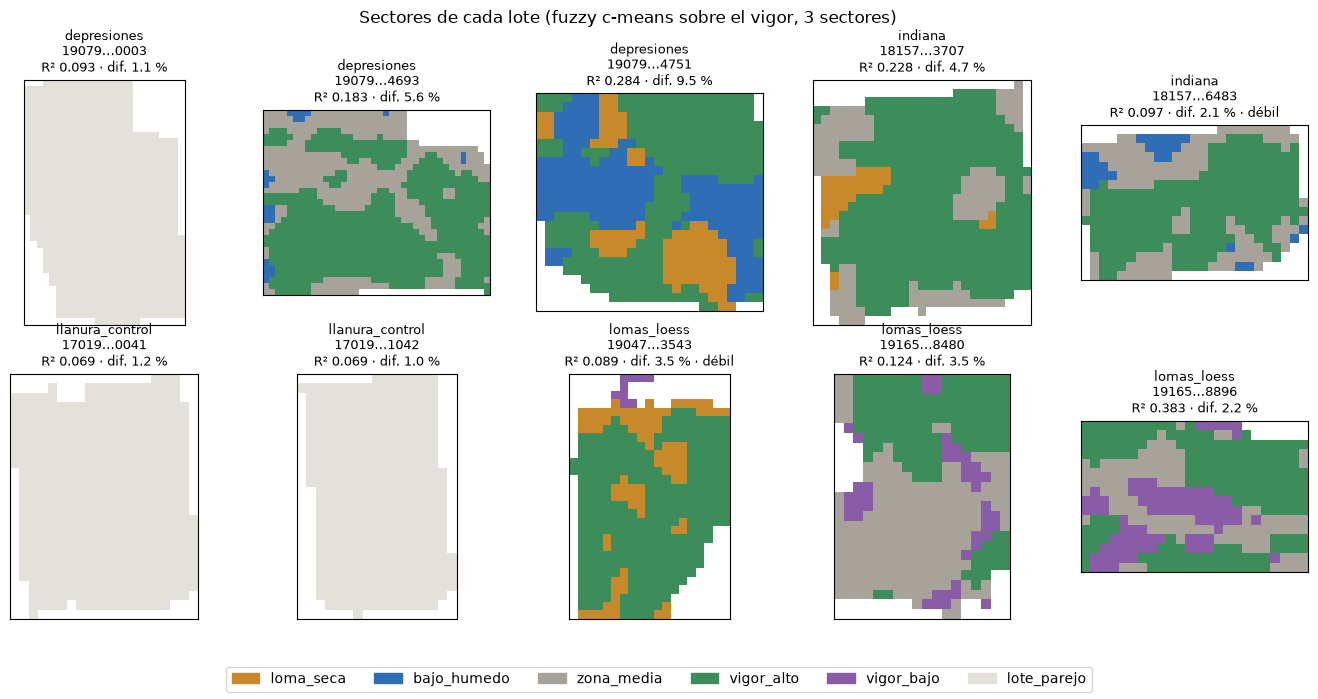

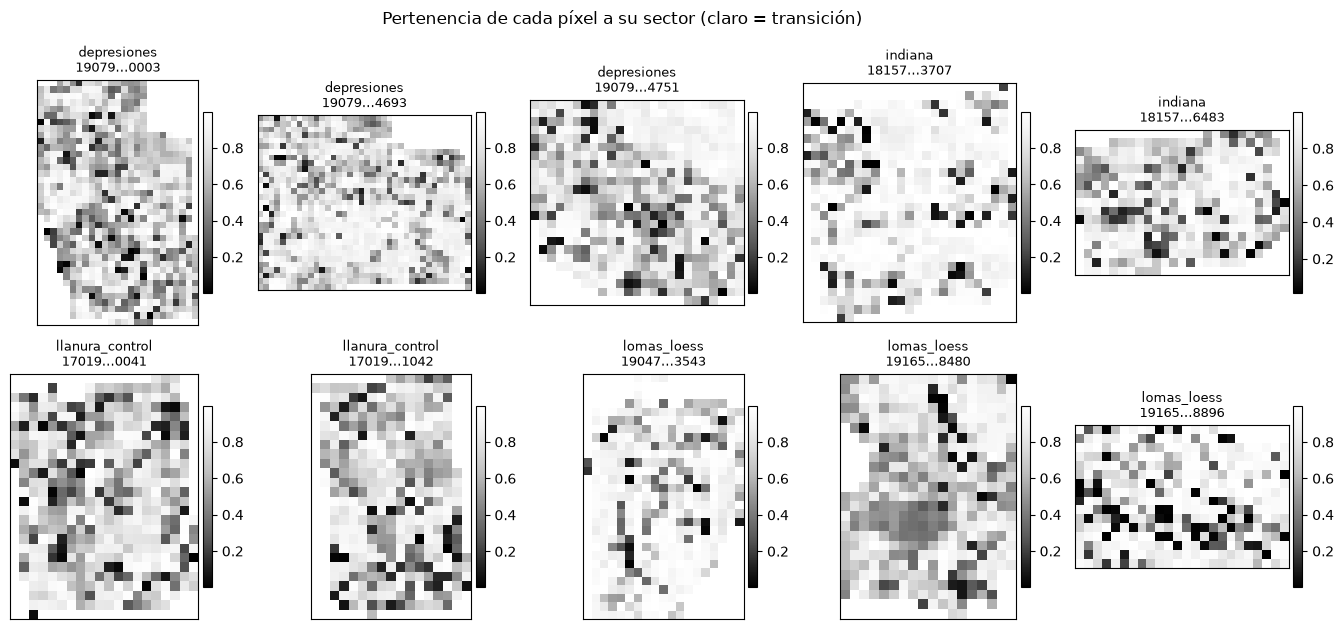

In [22]:
TIPOS_SECTOR = ["loma_seca", "bajo_humedo", "zona_media", "vigor_alto", "vigor_bajo", "lote_parejo"]
COLORES_SECTOR = ["#C8892B", "#2F6DB5", "#A8A39A", "#3C8D5A", "#8A5BA6", "#E4E1DA"]

if HAY_DATOS:
    mapa = sectores_px.merge(rasgos[["id_lote", "sector", "sector_id", "tipo", "estado_sectores"]],
                             on=["id_lote", "sector"])
    mapa.loc[mapa["estado_sectores"] == "lote_parejo", "tipo"] = "lote_parejo"
    sub = {i: f'R² {r.r2_validacion:.3f} · dif. {r.dif_vigor_validacion_pct:.1f} %'
              + (" · débil" if r.estado_sectores == "sectores_debiles" else "") for i, r in estado.iterrows()}
    dibujar_lotes(mapa, "tipo", "Sectores de cada lote (fuzzy c-means sobre el vigor, 3 sectores)",
                  categorias=TIPOS_SECTOR, colores=COLORES_SECTOR, subtitulos=sub)
    dibujar_lotes(mapa, "pertenencia", "Pertenencia de cada píxel a su sector (claro = transición)", cmap="Greys_r")
else:
    print("Faltan los datos de lotes: queda en espera.")

**Un lote de ejemplo, año por año.** Cada punto es un año: cuánto más o menos vigor tuvo cada sector que el promedio del lote, separado por tipo de año. Es lo que muestra la ficha del sector en la app.

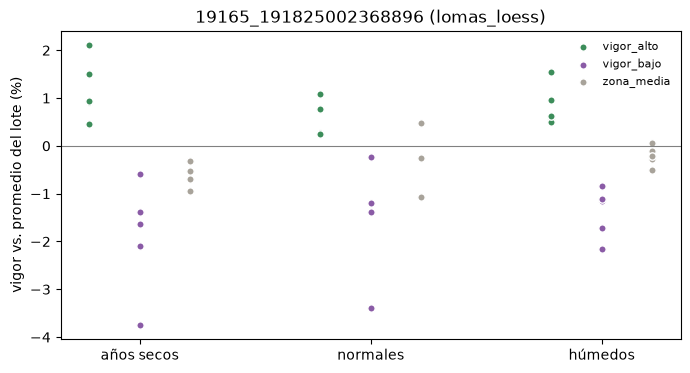

mediana                p10                p90             n_anios  \
clase_anio  humedo normal seco humedo normal seco humedo normal seco  humedo   
tipo                                                                           
vigor_alto     0.6    0.5  0.9    0.5    0.3  0.6    1.3    1.0  1.9     5.0   
vigor_bajo    -1.2   -1.3 -1.6   -2.0   -2.8 -3.1   -1.0   -0.5 -0.9     5.0   
zona_media    -0.2   -0.3 -0.5   -0.4   -0.8 -0.8   -0.0    0.3 -0.3     5.0   

                        
clase_anio normal seco  
tipo                    
vigor_alto    4.0  5.0  
vigor_bajo    4.0  5.0  
zona_media    4.0  5.0

In [23]:
if HAY_DATOS:
    con = estado[estado["estado_sectores"] == "con_sectores"]
    ejemplo = con["r2_validacion"].idxmax() if len(con) else lotes["id_lote"].iloc[0]
    s = serie[serie["id_lote"] == ejemplo].merge(rasgos[["id_lote", "sector", "tipo"]], on=["id_lote", "sector"])
    fig, eje = plt.subplots(figsize=(8, 4))
    pos = {"seco": 0, "normal": 1, "humedo": 2}
    colores = dict(zip(TIPOS_SECTOR, COLORES_SECTOR))
    for j, (tipo, t) in enumerate(s.groupby("tipo")):
        x = t["clase_anio"].map(pos) + (j - 1) * 0.22
        eje.scatter(x, t["vigor_rel_pct"], color=colores[tipo], label=tipo, s=28, edgecolor="white")
    eje.axhline(0, color="gray", lw=0.8)
    eje.set_xticks(range(3)); eje.set_xticklabels(["años secos", "normales", "húmedos"])
    eje.set_ylabel("vigor vs. promedio del lote (%)")
    eje.set_title(f"{ejemplo} ({lotes.set_index('id_lote').loc[ejemplo, 'paisaje']})")
    eje.legend(frameon=False, fontsize=8)
    plt.show()
    display(por_clase[por_clase["id_lote"] == ejemplo]
            .merge(rasgos[["id_lote", "sector", "tipo"]], on=["id_lote", "sector"])
            .pivot(index="tipo", columns="clase_anio", values=["mediana", "p10", "p90", "n_anios"]).round(1))
else:
    print("Faltan los datos de lotes: queda en espera.")

## 15. Guardar las tablas

Tres tablas en `data/ml/` (CSV, claves primero, faltante = celda vacía):

- `punto1_sectores.csv`: un píxel por fila: `fips, id_lote, px_id, estado_sectores, sector_id, tipo, pertenencia`. En los lotes parejos, `sector_id`, `tipo` y `pertenencia` quedan vacíos.
- `punto1_sectores_resumen.csv`: un sector por fila: superficie, rasgos (terreno 3DEP, suelo, drenaje con caños, % de otro cultivo), confianza y el resultado de la validación del lote. Los lotes parejos van en una sola fila, sin sector.
- `punto1_sectores_anual.csv`: un sector por año: `vigor_rel_pct`, tipo de año, cultivo y cantidad de imágenes.

De acá sale después lo que lee el front (`sectores/<id_lote>.geojson` y `.json`): eso todavía no está.

In [24]:
CARPETA_SALIDA = RAIZ / "data" / "ml"

if HAY_DATOS:
    CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)
    m = mapa.copy()
    parejo = m["estado_sectores"] == "lote_parejo"
    m["sector_id"] = m["sector_id"].astype("Int64").mask(parejo)
    m["tipo"] = m["tipo"].mask(parejo)
    m["pertenencia"] = m["pertenencia"].mask(parejo)
    m[["fips", "id_lote", "px_id", "estado_sectores", "sector_id", "tipo", "pertenencia"]] \
        .sort_values(["id_lote", "px_id"]).round(3) \
        .to_csv(CARPETA_SALIDA / "punto1_sectores.csv", index=False)

    # Lotes con sectores: una fila por sector. Lotes parejos: una sola fila, sin sector.
    cols = ["fips", "id_lote", "estado_sectores", "sector_id", "tipo", "n_px", "area_ha", "pct_lote",
            "confianza", "pct_anios_consistente", "pertenencia_media", "elev_rel_m", "pendiente_3dep_pct",
            "twi_3dep", "aws0_150_mm", "clase_drenaje", "pct_drenaje_canos", "pct_otro_cultivo",
            "vigor_medio_z", "vigor_seco_z", "vigor_humedo_z",
            "r2_validacion", "dif_vigor_validacion_pct", "anios_validacion"]
    con_sectores = rasgos[rasgos["estado_sectores"] != "lote_parejo"]
    parejos = (rasgos[rasgos["estado_sectores"] == "lote_parejo"]
               .groupby(["fips", "id_lote"], as_index=False)
               .agg(estado_sectores=("estado_sectores", "first"), n_px=("n_px", "sum"),
                    r2_validacion=("r2_validacion", "first"),
                    dif_vigor_validacion_pct=("dif_vigor_validacion_pct", "first"),
                    anios_validacion=("anios_validacion", "first")))
    parejos["area_ha"] = parejos["n_px"] * 0.09
    salida = pd.concat([con_sectores, parejos], ignore_index=True).reindex(columns=cols)
    salida["sector_id"] = salida["sector_id"].astype("Int64")
    salida.sort_values(["id_lote", "sector_id"]).round(3) \
        .to_csv(CARPETA_SALIDA / "punto1_sectores_resumen.csv", index=False)

    a = serie.merge(rasgos[["id_lote", "sector", "sector_id", "estado_sectores"]], on=["id_lote", "sector"])
    a = a[a["estado_sectores"] != "lote_parejo"]
    a[["fips", "id_lote", "sector_id", "anio", "cultivo", "clase_anio", "vigor_rel_pct", "n_px_con_dato",
       "n_obs_jul_ago"]].sort_values(["id_lote", "sector_id", "anio"]).round(2) \
        .to_csv(CARPETA_SALIDA / "punto1_sectores_anual.csv", index=False)

    for f in ["punto1_sectores.csv", "punto1_sectores_resumen.csv", "punto1_sectores_anual.csv"]:
        print(f, len(pd.read_csv(CARPETA_SALIDA / f)), "filas")
else:
    print("Faltan los datos de lotes: queda en espera.")

punto1_sectores.csv 5334 filas
punto1_sectores_resumen.csv 24 filas
punto1_sectores_anual.csv 315 filas


## Próximos pasos

- [ ] Revisar los sectores con alguien que conozca la zona, mirando los mapas junto con una imagen satelital: los sectores chicos (1–4 % del lote) pueden ser vías de agua o bajos que se anegan.
- [ ] Acordar con el front cómo se muestra `sectores_debiles`: `estado_sectores` es un campo firme del contrato (`INFO.md`), así que sumarlo sube la versión a 1.0. Sumar también los tipos nuevos (`vigor_alto`, `vigor_bajo`) y `textos.json`.
- [ ] Generar lo que lee el front: `sectores/<id_lote>.geojson` (polígonos a partir de la grilla) y `sectores/<id_lote>.json` (ficha), con `version_contrato`.
- [ ] Repetir cuando lleguen más pasadas de Landsat: hoy 26 de los 260 lote-años no tienen ninguna de julio–agosto (7 en 2009, 6 en 2024). Sentinel-2 no sirve para llenarlos por ahora: su vigor relativo coincide poco con el de Landsat (correlación mediana 0,53).
- [ ] Probar el lidar de 1 m de 3DEP si llega (hoy se usa el DEM de 10 m).
- [ ] Revisar los umbrales (R², diferencia de vigor, consistencia, otro cultivo, nombres) con más lotes.
- [ ] Revisar si conviene pasar a 4 sectores: con la v1.3, de 3 a 4 el R² sube 0,04.
- [ ] Mirar la estabilidad de los sectores ante cambios chicos en los datos: en un lote (19165_…368896), sacar unos 8 píxel-años con otro cultivo cambió bastante la partición (ARI 0,60 contra la anterior) y su "loma seca" pasó a "zona media". Con otras semillas, en cambio, los sectores no cambian (ARI de 0,98 o más).
- [ ] Prender `MIRAR_TEST` una sola vez, al final.
- [ ] Escribir `docs/ml/model_card_punto1.md`.
- [ ] Definir con el punto 2 cómo se pasa de sus puntos (`point_id`, en Story, McLean y Sumner) a estos lotes (`id_lote`, en otros condados).